# 04 — Melanjutkan embedding dengan benchmark dan cache v1

**Run sumber:** `20261020_080413_928636_text_embeddings`  
**Run lanjutan:** `20261020_080413_928636_text_embeddings_accelerated`

Notebook ini menggantikan versi tahap 04 sebelumnya. Kohort, fitur, **X/y terpisah**, dan prediksi sejak jam ke-4 tetap sama. Optimasi hanya pada cara komputasi embedding BioClinicalBERT beku.

1. **Migrasi terverifikasi:** audit katalog terhadap semua dokumen sumber tahap 02, periksa hash dan tokenisasi checkpoint lama, lalu rujuk array lama tanpa menghitungnya ulang. Katalog disalin sebagai snapshot lokal; array checkpoint lama tidak diduplikasi.
2. **Benchmark:** bandingkan CPU/thread/batch dan CUDA bila tersedia dengan float32/eager. Batching lintas dokumen mengelompokkan chunk menurut panjang. Hasil harus konsisten dengan baseline CPU.
3. **Cache v1:** hanya gunakan chunk v1 yang cocok teks, model, tokenizer, token, offset, dan bobot overlap. Dokumen, jam ketersediaan, dan pengaitan tetap berasal dari v2.
4. **Build:** gunakan konfigurasi tercepat yang lulus benchmark, lanjutkan teks yang belum selesai, kemudian periksa seluruh agregasi dan re-inference sampel.

**Jangan hapus folder run sumber.** Hasil lanjutan merujuk checkpoint di folder itu. Jangan menjalankan run lama dan lanjutan bersamaan. Semua teks, token ID, indeks `_LOCAL`, dan embedding tetap di PC berwenang.

## 1. Cara menjalankan

**Pertama:** Interrupt proses lama melalui tombol ■, tunggu proses berhenti, simpan notebook, lalu **Restart Kernel**. Ganti file notebook tahap 04 dengan versi ini.

Pengaturan awal sudah `MODE='benchmark'`. Pilih kernel Python Windows yang sama, kemudian **Run All**. Ini melakukan audit/migrasi dan pengukuran; belum menjalankan embedding penuh. Audit pertama dapat memerlukan waktu karena semua checkpoint lama dan kandidat cache harus diperiksa.

Setelah muncul **`BENCHMARK_COMPLETE`**, ubah hanya `MODE='build'`, **Restart Kernel → Run All**. Tidak perlu mengubah batch/device sendiri. Jika build terputus, tetap gunakan MODE build dan run lanjutan yang sama.

Tidak ada instalasi/penggantian PyTorch/CUDA otomatis. Jangan pindahkan data MIMIC ke layanan lain untuk menjalankan notebook ini.

In [1]:
from pathlib import Path
import os
os.environ.setdefault('USE_TF','0')
os.environ.setdefault('USE_FLAX','0')
os.environ.setdefault('TOKENIZERS_PARALLELISM','false')
ROOT=Path(r'C:\Users\ASUS\Documents\icu_los')
V1_ROOT=Path(r'C:\Users\ASUS\Documents\dgt_los')
STAGE03_RUN='20261020_072544_551159_preprocess'
SOURCE_RUN='20261020_080413_928636_text_embeddings'
ACCELERATED_RUN=SOURCE_RUN+'_accelerated'
MODE='build'  # pertama benchmark; setelah BENCHMARK_COMPLETE ubah menjadi build
USE_V1_CACHE=True
LOCAL_FILES_ONLY=True  # model/tokenizer sudah dipakai run sumber
MIN_FREE_GIB=40.0
BENCHMARK_DOCUMENTS=24
print('Source:',SOURCE_RUN)
print('Continuation:',ACCELERATED_RUN)
print('Mode:',MODE)

Source: 20261020_080413_928636_text_embeddings
Continuation: 20261020_080413_928636_text_embeddings_accelerated
Mode: build


## 2. Verifikasi sumber dan utilitas

Snapshot database tahap 02 tetap read-only. Hash awalnya telah dicatat pada run lama; ukuran, mtime, hash yang dipin, dan identitas sumber tahap 03 harus cocok. Migrasi mengaudit ulang teks dan metadata katalog terhadap sumber tahap 02.

Tidak ada nilai target LOS yang dipakai untuk tokenisasi, matching cache, benchmark, atau pemilihan konfigurasi kecepatan.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import contextmanager
from collections import Counter
import os, json, hashlib, sqlite3, time, re, math, shutil, platform, inspect, threading
import numpy as np
import pandas as pd

MODEL_ID = 'emilyalsentzer/Bio_ClinicalBERT'
READY = 'TEXT_EMBEDDINGS_COMPLETE_READY_FOR_MODEL_DESIGN'
DEATH = re.compile(r'\b(?:pronounced\s+dead|time\s+of\s+death|patient\s+(?:died|expired)|pt\s+(?:died|expired))\b', re.I)

def require(ok, message):
    if not bool(ok): raise ValueError(message)

def clean_text(text):
    return re.sub(r'\s+', ' ', str(text).replace('\x00', ' ')).strip()

def atomic_json(path, obj):
    path=Path(path); tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    os.replace(tmp,path)

def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))

def sha(path):
    h=hashlib.sha256(); size=Path(path).stat().st_size; done=0; last=time.monotonic()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):
            h.update(chunk);done+=len(chunk)
            if time.monotonic()-last>25:
                print(f'Integrity scan: {done/2**30:.2f}/{size/2**30:.2f} GiB',flush=True);last=time.monotonic()
    return h.hexdigest()

def artifact(path):
    p=Path(path);s=p.stat()
    return dict(path=str(p.resolve()),bytes=s.st_size,mtime_ns=s.st_mtime_ns,sha256=sha(p))

def verify_artifact(a):
    p=Path(a['path'])
    require(p.is_file() and p.stat().st_size==a['bytes'] and sha(p)==a['sha256'], 'Artefak berubah: '+p.name)

@contextmanager
def locked(path):
    f=open(path,'a+b');f.seek(0);f.write(b'0');f.flush();f.seek(0)
    try:
        if os.name=='nt':
            import msvcrt;msvcrt.locking(f.fileno(),msvcrt.LK_NBLCK,1)
        else:
            import fcntl;fcntl.flock(f.fileno(),fcntl.LOCK_EX|fcntl.LOCK_NB)
    except (OSError,BlockingIOError):
        f.close();raise RuntimeError('Run sedang aktif. Jangan jalankan dua kernel untuk run yang sama.')
    try: yield
    finally:
        f.seek(0)
        if os.name=='nt': msvcrt.locking(f.fileno(),msvcrt.LK_UNLCK,1)
        else: fcntl.flock(f.fileno(),fcntl.LOCK_UN)
        f.close()

@contextmanager
def heartbeat(label):
    stop=threading.Event();start=time.monotonic()
    def report():
        while not stop.wait(25): print(f'{label}: masih berjalan ({(time.monotonic()-start)/60:.1f} menit)',flush=True)
    thread=threading.Thread(target=report,daemon=True);thread.start()
    try: yield
    finally: stop.set();thread.join(timeout=1)

def ro_db(path):
    db=sqlite3.connect(Path(path).resolve().as_uri()+'?mode=ro&immutable=1',uri=True)
    db.execute('PRAGMA query_only=ON');return db

def code_hash():
    # Canonical code fields: marshal reference/intern flags can change after execution.
    import types
    def value(x):
        if isinstance(x,types.CodeType):
            return dict(bytecode=x.co_code.hex(),constants=[value(v) for v in x.co_consts],names=x.co_names,varnames=x.co_varnames,
                        freevars=x.co_freevars,cellvars=x.co_cellvars,args=x.co_argcount,posonly=x.co_posonlyargcount,
                        kwonly=x.co_kwonlyargcount,flags=x.co_flags,exceptions=getattr(x,'co_exceptiontable',b'').hex())
        if isinstance(x,tuple):return {'tuple':[value(v) for v in x]}
        if isinstance(x,frozenset):return {'frozenset':sorted([value(v) for v in x],key=repr)}
        if isinstance(x,bytes):return {'bytes':x.hex()}
        if x is None or isinstance(x,(str,int,float,bool)):return x
        return {'type':type(x).__name__,'repr':repr(x)}
    payload={k:value(inspect.unwrap(globals()[k]).__code__) for k in ENGINE_FUNCTIONS}
    return hashlib.sha256(json.dumps(payload,sort_keys=True,ensure_ascii=True).encode()).hexdigest()


def prepare_sources(root, stage03_run):
    r=Path(root)/'outputs'/stage03_run; mp=r/'run_metadata.json';m=load_json(mp)
    require(m['status']=='SPLIT_PREPROCESS_COMPLETE_READY_FOR_TEXT_EMBEDDINGS','Tahap 03 belum COMPLETE')
    package_path=Path(m['input_package']);require(sha(package_path)==m['input_package_sha256'],'Package tahap 03 berubah')
    package=load_json(package_path)
    require(package['fit_scope']=='TRAIN_ONLY_SEPARATE_PER_FOLD' and not package['target_feature'],'Kontrak preprocessing berbeda')
    s2path=Path(root)/'outputs'/m['stage02_run']/'run_metadata.json';s2=load_json(s2path)
    require(s2['status']=='SEQUENCES_COMPLETE_READY_FOR_SPLIT_PREPROCESS','Tahap 02 belum COMPLETE')
    require(s2['cohort_sha256']==m['cohort_sha256']==package['cohort_sha256'],'Kohort tahap 02/03 berbeda')
    contract_path=Path(s2['report_directory'])/'sequence_contract.json'
    require(sha(contract_path)==s2['sequence_contract_sha256'],'Kontrak tahap 02 berubah')
    contract=load_json(contract_path)
    require(all(package[k]==contract[k] for k in ['notes_database','notes_table','diagnosis_file','row_map']),'Sumber teks/row map tidak sama')
    require(package['notes_table']=='notes' and package['prediction']['first_hour']==4,'Kontrak jadwal/table berbeda')
    # Small source artifacts are matched to the already-sealed stage03 receipt.
    paths=[mp,package_path,s2path,contract_path,Path(package['row_map']),Path(package['sequence_index']),Path(package['diagnosis_file'])]
    for rr in [r,Path(s2['report_directory'])]:
        q=rr/'quality_checks.csv';require(pd.read_csv(q).status.eq('PASS').all(),'Quality checks sumber tidak semua PASS');paths.append(q)
    indexed={str(Path(a['path']).resolve()):a for a in m['output_artifacts']+m['sources']}
    for p in [package_path,Path(package['row_map']),Path(package['sequence_index'])]:
        entry=indexed.get(str(p.resolve()));require(entry is not None,'Sumber tidak tercantum dalam receipt tahap 03');verify_artifact(entry)
    # Diagnosis CSV was sealed separately by stage02; verify against cohort values below.
    cohort_path=Path(s2['stage01_data_directory'])/'cohort_LOCAL.csv'
    require(sha(cohort_path)==s2['cohort_sha256'],'Kohort sumber berubah');paths.append(cohort_path)
    cols=['cohort_row','ICUSTAY_ID','INTIME','DIAGNOSIS','DIAGNOSIS_AVAILABLE_TIME_PROXY','diagnosis_present','diagnosis_available_hour']
    cohort=pd.read_csv(cohort_path,usecols=cols,keep_default_na=False)
    sample=pd.read_csv(package['row_map']);seq=pd.read_csv(package['sequence_index'])
    n=len(sample)
    require(n==s2['counts']['cohort_stays']==m['counts']['cohort_stays'],'Jumlah kohort berbeda')
    require(np.array_equal(sample.cohort_row,np.arange(n)) and sample.ICUSTAY_ID.is_unique,'Row map invalid')
    require(np.array_equal(cohort.ICUSTAY_ID,sample.ICUSTAY_ID) and np.array_equal(cohort.cohort_row,sample.cohort_row),'Urutan kohort berbeda')
    require(np.array_equal(seq.ICUSTAY_ID,sample.ICUSTAY_ID) and np.array_equal(seq.cohort_row,sample.cohort_row),'Urutan sequence berbeda')
    require(seq.first_prediction_hour.eq(4).all() and seq.last_prediction_hour.ge(4).all(),'Jadwal invalid')
    diagnosis=pd.read_csv(package['diagnosis_file'],keep_default_na=False)
    require(list(diagnosis.columns)==['cohort_row','ICUSTAY_ID','DIAGNOSIS','DIAGNOSIS_AVAILABLE_TIME_PROXY','diagnosis_present','diagnosis_available_hour'],'Schema diagnosis berbeda')
    require(diagnosis.astype(str).equals(cohort[diagnosis.columns].astype(str)),'Diagnosis tidak sama dengan kohort sumber')
    intime=pd.to_datetime(cohort.INTIME,errors='raise').astype('int64').to_numpy()//10**9
    return dict(stage03=m,stage02=s2,package=package,sample=sample,seq=seq,diagnosis=diagnosis,intime=intime,
                small_sources=[artifact(p) for p in dict.fromkeys(paths)],db_path=Path(package['notes_database']))

def source_db_guard(inputs, data):
    p=inputs['db_path'];require(not Path(str(p)+'-wal').exists() or Path(str(p)+'-wal').stat().st_size==0,'Database sumber memiliki WAL aktif')
    st=p.stat();expected=inputs['stage02']['database_sha256'];receipt=data/'source_database_verification.json'
    identity=dict(path=str(p.resolve()),bytes=st.st_size,mtime_ns=st.st_mtime_ns,sha256=expected)
    if receipt.exists():
        require(load_json(receipt)==identity,'Identitas database sumber berubah sejak awal run')
        print('Database sumber: memakai verifikasi hash tersimpan; ukuran/mtime tetap.',flush=True)
    else:
        print('Verifikasi awal database sumber (read-only)...',flush=True)
        require(sha(p)==expected,'Hash database tahap 02 berbeda')
        atomic_json(receipt,identity)
    return identity




## 3. Tokenisasi dan definisi pooling tetap

Whitespace dirapikan, tanpa stemming atau penghapusan angka/negasi. Maksimum 510 token isi + `[CLS]/[SEP]`, overlap 64. Vektor chunk memakai mean token isi. Vektor dokumen mengoreksi cakupan token overlap sebelum dirata-ratakan.

Katalog sumber menyimpan semua dokumen yang diterima tahap 02. Pemanfaatan cache tidak menghapus duplikat dokumen atau mengubah waktu ketersediaannya.

In [3]:
def catalog_open(data):
    db=sqlite3.connect(data/'text_catalog_LOCAL.sqlite')
    db.executescript('''
    PRAGMA journal_mode=WAL;
    PRAGMA synchronous=FULL;
    CREATE TABLE IF NOT EXISTS content(uid INTEGER PRIMARY KEY,hash TEXT UNIQUE NOT NULL,text TEXT NOT NULL);
    CREATE TABLE IF NOT EXISTS docs(kind TEXT NOT NULL,sid INTEGER NOT NULL,row_no INTEGER NOT NULL,hour REAL NOT NULL,bin INTEGER NOT NULL,uid INTEGER NOT NULL,category TEXT,los_flag INTEGER,disposition_flag INTEGER,PRIMARY KEY(kind,sid));
    CREATE TABLE IF NOT EXISTS state(key TEXT PRIMARY KEY,value TEXT NOT NULL);
    CREATE TABLE IF NOT EXISTS skipped(reason TEXT PRIMARY KEY,n INTEGER NOT NULL);
    CREATE INDEX IF NOT EXISTS docs_hour ON docs(kind,row_no,bin,sid);
    CREATE INDEX IF NOT EXISTS docs_content ON docs(uid);
    ''');db.commit();return db

def state_get(db,key,default=None):
    r=db.execute('SELECT value FROM state WHERE key=?',(key,)).fetchone();return json.loads(r[0]) if r else default

def state_set(db,key,value):
    db.execute('INSERT OR REPLACE INTO state VALUES (?,?)',(key,json.dumps(value)))

def insert_doc(db,kind,sid,row,hour,text,category='',los=0,disposition=0):
    clean=clean_text(text);require(bool(clean),'Teks kosong masuk katalog')
    digest=hashlib.sha256(clean.encode()).hexdigest()
    # No OR IGNORE on an INTEGER AUTOINCREMENT key: content indices remain dense.
    found=db.execute('SELECT uid,text FROM content WHERE hash=?',(digest,)).fetchone()
    if found:
        uid=found[0];require(found[1]==clean,'SHA collision: teks tidak sama')
    else:
        uid=db.execute('INSERT INTO content(hash,text) VALUES (?,?)',(digest,clean)).lastrowid
    db.execute('INSERT INTO docs VALUES (?,?,?,?,?,?,?,?,?)',(kind,int(sid),int(row),float(hour),math.floor(hour),int(uid),category,int(los),int(disposition)))

def build_catalog(inputs, data):
    db=catalog_open(data)
    try:
        return populate_catalog(inputs,db)
    except BaseException:
        db.rollback();db.close();raise

def populate_catalog(inputs, db):
    n=len(inputs['sample']);last=inputs['seq'].last_prediction_hour.to_numpy()
    if not state_get(db,'diagnosis_done',False):
        counts=Counter()
        for r in inputs['diagnosis'].itertuples(index=False):
            text=clean_text(r.DIAGNOSIS);row=int(r.cohort_row)
            if not text: counts['diagnosis_blank_after_cleaning']+=1;continue
            h=pd.to_numeric(r.diagnosis_available_hour,errors='coerce')
            if not np.isfinite(h): counts['diagnosis_invalid_availability']+=1;continue
            if h>=last[row]: counts['diagnosis_after_last_prediction']+=1;continue
            proxy=pd.to_datetime(r.DIAGNOSIS_AVAILABLE_TIME_PROXY,errors='coerce')
            require(pd.notna(proxy),'Diagnosis proxy invalid')
            actual=(proxy.value/10**9-inputs['intime'][row])/3600
            require(abs(actual-h)<1e-8 and int(r.diagnosis_present)==1,'Diagnosis availability tidak cocok')
            insert_doc(db,'diagnosis',int(r.ICUSTAY_ID),row,h,text)
        for reason,c in counts.items(): db.execute('INSERT INTO skipped VALUES (?,?)',(reason,c))
        state_set(db,'diagnosis_done',True);db.commit()
        print('Diagnosis catalog selesai; belum ada embedding.',flush=True)
    mapping=dict(zip(inputs['sample'].ICUSTAY_ID,inputs['sample'].cohort_row));cursor=state_get(db,'last_rid',-1)
    if not state_get(db,'notes_done',False):
        source=ro_db(inputs['db_path'])
        try:
            while True:
                rows=source.execute('SELECT rid,icu,ct,av,h,category,text_hash,text,LOS_flag,disposition_flag FROM notes WHERE rid>? ORDER BY rid LIMIT 2000',(cursor,)).fetchall()
                if not rows: break
                for rid,icu,ct,av,h,category,digest,text,los,disposition in rows:
                    require(icu in mapping,'Catatan di luar kohort');row=int(mapping[icu]);hour=(av-int(inputs['intime'][row]))/3600
                    require(ct>=inputs['intime'][row] and av>=ct and math.floor(hour)==h and 0<=hour<last[row],'Jam note/linkage berbeda')
                    clean=clean_text(text)
                    require(clean and hashlib.sha256(clean.encode()).hexdigest()==digest,'Isi/hash note berbeda')
                    require(category and category.casefold()!='discharge summary' and not DEATH.search(clean),'Note melanggar kebijakan eksklusi tahap 02')
                    insert_doc(db,'note',rid,row,hour,clean,category,los,disposition)
                cursor=int(rows[-1][0]);state_set(db,'last_rid',cursor)
                # Progress count is a persisted counter, to avoid repeated full COUNT scans.
                processed=state_get(db,'note_count',0)+len(rows);state_set(db,'note_count',processed);db.commit()
                if processed%20000<2000: print(f'Catalog notes: {processed:,}/{inputs["stage02"]["counts"]["note_documents"]:,}',flush=True)
            require(state_get(db,'note_count',0)==inputs['stage02']['counts']['note_documents'],'Jumlah note berbeda')
            state_set(db,'notes_done',True);db.commit()
        finally: source.close()
    counts=dict(db.execute('SELECT kind,COUNT(*) FROM docs GROUP BY kind').fetchall())
    require(counts.get('note',0)==inputs['stage02']['counts']['note_documents'],'Notes hilang/duplikat saat katalog')
    unique=db.execute('SELECT COUNT(*),MIN(uid),MAX(uid) FROM content').fetchone()
    require(unique[0]>0 and unique[1]==1 and unique[2]==unique[0],'UID konten tidak rapat')
    require(counts.get('diagnosis',0)+sum(x[0] for x in db.execute('SELECT n FROM skipped'))==n,'Disposition diagnosis tidak rekonsiliasi')
    print(f'Catalog COMPLETE: {sum(counts.values()):,} dokumen; {unique[0]:,} teks unik. Duplikat dokumen tetap dipertahankan.',flush=True)
    return db,counts,unique[0]


def spans(total, capacity=510, overlap=64):
    require(total>0 and 0<=overlap<capacity,'Token count/overlap invalid')
    start=0
    while True:
        stop=min(start+capacity,total);yield start,stop
        if stop==total: break
        start=stop-overlap

def token_record(text, tokenizer, overlap):
    encoded=tokenizer(text,add_special_tokens=False,truncation=False,return_offsets_mapping=True,return_attention_mask=False,return_token_type_ids=False)
    ids=np.asarray(encoded['input_ids'],dtype=np.int32);offsets=np.asarray(encoded['offset_mapping'],dtype=np.int32)
    require(len(ids)>0 and offsets.shape==(len(ids),2),'Tokenisasi kosong/offset invalid')
    ss=list(spans(len(ids),510,overlap));coverage=np.zeros(len(ids),dtype=np.int32)
    for a,b in ss: coverage[a:b]+=1
    require((coverage>0).all(),'Token tidak tercakup chunk')
    weights=[(1.0/coverage[a:b]).astype(np.float32) for a,b in ss]
    require(np.allclose(sum(float(w.astype(np.float64).sum()) for w in weights),len(ids),atol=1e-5,rtol=1e-7),'Bobot cakupan tidak satu per token')
    return ids,offsets,ss,weights


def load_encoder(data, requested_revision, device, threads, local_only):
    # Only imported in stage04; never instantiate an optimizer.
    import torch, transformers
    from transformers import AutoConfig, AutoTokenizer, AutoModel
    torch.set_num_threads(threads)
    config=AutoConfig.from_pretrained(MODEL_ID,revision=requested_revision,local_files_only=local_only)
    revision=getattr(config,'_commit_hash',None)
    require(revision and re.fullmatch('[0-9a-f]{40}',revision),'Checkpoint commit belum resolved')
    require(config.model_type=='bert' and config.hidden_size==768 and config.max_position_embeddings==512,'Checkpoint bukan BioClinicalBERT yang diharapkan')
    tok=AutoTokenizer.from_pretrained(MODEL_ID,revision=revision,use_fast=True,local_files_only=local_only)
    require(tok.is_fast and tok.num_special_tokens_to_add(pair=False)==2 and len(tok)==config.vocab_size,'Tokenizer tidak cocok')
    require(tok.build_inputs_with_special_tokens([tok.unk_token_id])==[tok.cls_token_id,tok.unk_token_id,tok.sep_token_id],'Wrapper tokenizer bukan BERT CLS/SEP')
    tokdir=data/'tokenizer'
    if tokdir.exists():
        saved=AutoTokenizer.from_pretrained(tokdir,use_fast=True,local_files_only=True)
        require(saved.backend_tokenizer.to_str()==tok.backend_tokenizer.to_str(),'Tokenizer checkpoint berubah')
    else: tok.save_pretrained(tokdir)
    print('Memuat BioClinicalBERT beku (pertama kali dapat mengunduh checkpoint)...',flush=True)
    with heartbeat('Memuat encoder'):
        model=AutoModel.from_pretrained(MODEL_ID,revision=revision,local_files_only=local_only,attn_implementation='eager')
        model.requires_grad_(False);model.eval();model.to(device=device,dtype=torch.float32)
    require(not model.training and not any(p.requires_grad for p in model.parameters()),'Encoder tidak beku/eval')
    return model,tok,dict(model_id=MODEL_ID,revision=revision,hidden_size=768,device=device,dtype='float32',attention='eager',threads=threads,
                          python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,torch=torch.__version__,transformers=transformers.__version__,
                          tokenizer_sha256=hashlib.sha256(tok.backend_tokenizer.to_str().encode()).hexdigest())

def infer_document(text, model, tokenizer, device, overlap=64, batch_size=1):
    import torch
    ids,offsets,ss,weights=token_record(text,tokenizer,overlap)
    vectors=[];numerators=[];sums=[]
    for base in range(0,len(ss),batch_size):
        group=ss[base:base+batch_size];length=max(b-a+2 for a,b in group)
        x=np.full((len(group),length),tokenizer.pad_token_id,dtype=np.int64);mask=np.zeros_like(x)
        for i,(a,b) in enumerate(group):
            seq=[tokenizer.cls_token_id]+ids[a:b].tolist()+[tokenizer.sep_token_id]
            x[i,:len(seq)]=seq;mask[i,:len(seq)]=1
        with torch.inference_mode():
            hidden=model(input_ids=torch.as_tensor(x,device=device),attention_mask=torch.as_tensor(mask,device=device),token_type_ids=torch.zeros_like(torch.as_tensor(x,device=device))).last_hidden_state
            for i,(a,b) in enumerate(group):
                # Position slicing excludes only inserted wrappers/padding, including literal special IDs in content.
                content=hidden[i,1:1+b-a].float();w=weights[base+i]
                vectors.append(content.mean(0).cpu().numpy().copy())
                numerators.append((content*torch.as_tensor(w,device=device).unsqueeze(1)).sum(0).cpu().numpy().copy())
                sums.append(float(w.astype(np.float64).sum()))
    vec=np.asarray(vectors,dtype=np.float32);nums=np.asarray(numerators,dtype=np.float32)
    document=(nums.sum(axis=0,dtype=np.float64)/len(ids)).astype(np.float32)
    require(np.isfinite(vec).all() and np.isfinite(document).all(),'Embedding tidak finite')
    return dict(ids=ids,offsets=offsets,spans=np.asarray(ss,dtype=np.int32),chunk_vectors=vec,weighted_sums=nums,
                weight_totals=np.asarray(sums,dtype=np.float64),vector=document)



















## 4. Checkpoint, agregasi, dan loader

Array checkpoint lama diverifikasi lalu dirujuk, sedangkan checkpoint baru ditulis atomik. Notes dirata-ratakan dari dokumen **baru tersedia** per interval; interval kosong menjadi zero + mask, tanpa forward-fill teks.

Diagnosis dipakai sekali dan tetap time-gated pada jam proxy aktual. Pada prediksi jam 4, notes dengan availability tepat jam 4 belum boleh masuk; baru terlihat pada jam 5. Panjang akhir sequence dan waktu keluar ICU bukan fitur model.

Pemeriksaan penuh dilakukan untuk struktur, token, cakupan overlap, dan agregasi. Inferensi BERT ulang dilakukan pada sampel, bukan seluruh korpus.

In [4]:
def atomic_npz(path, arrays):
    path=Path(path);tmp=path.with_suffix('.tmp')
    with open(tmp,'wb') as f: np.savez(f,**arrays);f.flush();os.fsync(f.fileno())
    os.replace(tmp,path)

def embed_checkpoints(db,data,model,tok,settings,n_unique):
    folder=data/'checkpoints_LOCAL';folder.mkdir(exist_ok=True);ledger=[];start=time.monotonic();new=0;chunks=0
    total_blocks=math.ceil(n_unique/settings['documents_per_checkpoint']);last_log=0
    for block,lo in enumerate(range(1,n_unique+1,settings['documents_per_checkpoint'])):
        hi=min(n_unique+1,lo+settings['documents_per_checkpoint']);p=folder/f'block_{block:07d}.npz';commit=p.with_suffix('.json')
        if commit.exists():
            a=load_json(commit);require(a['first_uid']==lo and a['stop_uid']==hi,'Checkpoint UID berbeda');verify_artifact(a)
        else:
            require(shutil.disk_usage(data).free/2**30>=settings['min_free_gib'],'Disk reserve tercapai. Bebaskan ruang lalu resume.')
            arrays=checkpoint_arrays(db,lo,hi,model,tok,settings);atomic_npz(p,arrays)
            a=artifact(p);a.update(first_uid=lo,stop_uid=hi,documents=hi-lo,chunks=len(arrays['spans']),tokens=len(arrays['token_ids']))
            atomic_json(commit,a);new+=hi-lo
        ledger.append(a);chunks+=a['chunks']
        if time.monotonic()-last_log>=25 or block==total_blocks-1:
            rate=new/max(time.monotonic()-start,1e-6);eta=(n_unique-hi+1)/rate/3600 if rate else None
            eta_text=f'{eta:.1f} jam (perkiraan berjalan)' if eta is not None else 'belum tersedia';last_log=time.monotonic()
            print(f'Embedding {block+1:,}/{total_blocks:,}: {hi-1:,}/{n_unique:,} teks unik; chunks {chunks:,}; ETA {eta_text}',flush=True)
    return ledger

def validate_block(z,db,tokenizer,overlap,dim=768):
    uids=z['uids'];to=z['token_offsets'];co=z['chunk_offsets'];ids=z['token_ids'];chars=z['char_offsets'];ss=z['spans']
    require(len(to)==len(co)==len(uids)+1 and to[0]==co[0]==0 and to[-1]==len(ids)==len(chars) and co[-1]==len(ss),'Offset checkpoint invalid')
    require(z['document_vectors'].dtype==np.float32 and z['document_vectors'].shape==(len(uids),dim),'Vector dokumen invalid')
    require(z['chunk_vectors'].shape==z['weighted_sums'].shape==(len(ss),dim),'Vector chunk invalid')
    require(z['weight_totals'].shape==(len(ss),) and z['char_offsets'].shape==(len(ids),2),'Shape token/weight invalid')
    require(np.issubdtype(ids.dtype,np.integer) and np.all((ids>=0)&(ids<len(tokenizer))),'Token ID invalid')
    for name in ['chunk_vectors','weighted_sums','weight_totals','document_vectors']: require(np.isfinite(z[name]).all(),'Checkpoint NaN/infinite')
    for i,uid in enumerate(uids):
        a,b=map(int,to[i:i+2]);c,d=map(int,co[i:i+2]);total=b-a
        text=db.execute('SELECT text FROM content WHERE uid=?',(int(uid),)).fetchone()[0]
        require(total>0 and np.array_equal(ss[c:d],np.array(list(spans(total,510,overlap)))),'Rentang chunk tidak cocok')
        require(np.all(chars[a:b,0]>=0) and np.all(chars[a:b,1]<=len(text)) and np.all(chars[a:b,1]>chars[a:b,0]),'Offset karakter invalid')
        coverage=np.zeros(total,dtype=np.int32)
        for x,y in ss[c:d]: coverage[x:y]+=1
        expected=np.array([np.sum((1./coverage[x:y]).astype(np.float32),dtype=np.float64) for x,y in ss[c:d]])
        require(np.array_equal(expected,z['weight_totals'][c:d]),'Bobot overlap berbeda')
        reconstructed=(z['weighted_sums'][c:d].sum(0,dtype=np.float64)/total).astype(np.float32)
        require(np.array_equal(reconstructed,z['document_vectors'][i]),'Agregasi dokumen berbeda')


def build_representations(db,inputs,data,report,ledger,tok,model,settings,n_unique):
    out=data/'representations';out.mkdir(exist_ok=True);dim=768
    vecpath=out/'unique_document_vectors_LOCAL.npy'
    vectors=np.lib.format.open_memmap(vecpath,mode='w+',dtype='float32',shape=(n_unique,dim))
    token_counts=np.zeros(n_unique,dtype=np.int64);chunk_counts=np.zeros(n_unique,dtype=np.int64)
    print('Validasi semua checkpoint dan rekonstruksi dokumen...',flush=True)
    for i,a in enumerate(ledger):
        with np.load(a['path'],allow_pickle=False) as z:
            validate_block(z,db,tok,settings['overlap'],dim)
            idx=z['uids']-1;vectors[idx]=z['document_vectors'];token_counts[idx]=np.diff(z['token_offsets']);chunk_counts[idx]=np.diff(z['chunk_offsets'])
        if i%50==0 or i==len(ledger)-1: print(f'Checkpoint audit {i+1:,}/{len(ledger):,}',flush=True)
    vectors.flush();np.save(out/'unique_document_token_counts.npy',token_counts);np.save(out/'unique_document_chunk_counts.npy',chunk_counts)
    # Export indexes by streaming. No raw text is exported to reports or notebook outputs.
    for kind in ['diagnosis','note']:
        cursor=db.execute('SELECT sid AS source_id,row_no AS cohort_row,hour AS available_hour,bin AS available_bin,uid-1 AS vector_row,category,los_flag,disposition_flag FROM docs WHERE kind=? ORDER BY row_no,bin,sid',(kind,))
        file=out/f'{kind}_document_index_LOCAL.csv';first=True
        while True:
            rows=cursor.fetchmany(10000)
            if not rows: break
            frame=pd.DataFrame(rows,columns=[c[0] for c in cursor.description]);frame.to_csv(file,mode='w' if first else 'a',index=False,header=first);first=False
        if first: pd.DataFrame(columns=[c[0] for c in cursor.description]).to_csv(file,index=False)
    n=len(inputs['sample']);diag=np.lib.format.open_memmap(out/'diagnosis_vectors_LOCAL.npy',mode='w+',dtype='float32',shape=(n,dim));diag[:]=0
    dh=np.full(n,np.inf,dtype=np.float64);dp=np.zeros(n,dtype=np.uint8)
    for row,hour,uid in db.execute("SELECT row_no,hour,uid FROM docs WHERE kind='diagnosis'"):
        require(dp[row]==0,'Lebih dari satu diagnosis per ICU');diag[row]=vectors[uid-1];dh[row]=hour;dp[row]=1
    diag.flush();np.save(out/'diagnosis_available_hour_LOCAL.npy',dh);np.save(out/'diagnosis_present_LOCAL.npy',dp)
    sparse_index=[]
    with heartbeat('Menghitung interval notes tidak kosong'):
        groups=db.execute("SELECT COUNT(*) FROM (SELECT row_no,bin FROM docs WHERE kind='note' GROUP BY row_no,bin)").fetchone()[0]
    nv=np.lib.format.open_memmap(out/'note_interval_vectors_LOCAL.npy',mode='w+',dtype='float32',shape=(groups,dim))
    current=None;acc=np.zeros(dim,dtype=np.float64);count=0;g=0
    def flush_group():
        nonlocal g
        if current is not None:
            nv[g]=(acc/count).astype(np.float32);sparse_index.append((current[0],current[1],count));g+=1
            if g%10000==0: print(f'Agregasi notes interval {g:,}/{groups:,}',flush=True)
    for row,hour,uid in db.execute("SELECT row_no,bin,uid FROM docs WHERE kind='note' ORDER BY row_no,bin,sid"):
        key=(row,hour)
        if key!=current:
            flush_group();current=key;acc.fill(0);count=0
        acc+=vectors[uid-1];count+=1
    flush_group();require(g==groups,'Jumlah interval berbeda');nv.flush()
    si=np.array(sparse_index,dtype=np.int64).reshape(-1,3);np.save(out/'note_interval_index_LOCAL.npy',si)
    row_offsets=np.r_[0,np.cumsum(np.bincount(si[:,0],minlength=n))].astype(np.int64);np.save(out/'note_stay_offsets_LOCAL.npy',row_offsets)
    # Independent second pass: group in SQL; equal document means, including repeated text documents.
    print('Pemeriksaan ulang seluruh agregasi interval...',flush=True)
    independent=db.execute("SELECT row_no,bin,COUNT(*),GROUP_CONCAT(uid) FROM (SELECT row_no,bin,uid FROM docs WHERE kind='note' ORDER BY row_no,bin,sid) GROUP BY row_no,bin ORDER BY row_no,bin")
    checked_groups=0
    for i,(row,hour,count,uid_list) in enumerate(independent):
        require(np.array_equal(si[i],(row,hour,count)),'Urutan/count SQL interval berbeda')
        uids=[int(uid)-1 for uid in uid_list.split(',')];checked_groups+=1
        require(len(uids)==count and hour>=0 and hour<inputs['seq'].last_prediction_hour.iloc[row],'Indeks/count interval invalid')
        expected=vectors[uids].mean(0,dtype=np.float64).astype(np.float32)
        require(np.array_equal(expected,nv[i]),'Rerata interval berbeda')
        if i%10000==0: print(f'Interval audit {i+1:,}/{groups:,}',flush=True)
    require(checked_groups==groups and int(si[:,2].sum())==inputs['stage02']['counts']['note_documents'],'Dokumen note hilang di agregasi')
    np.save(out/'icustay_ids_LOCAL.npy',inputs['sample'].ICUSTAY_ID.to_numpy(dtype=np.int64))
    # Re-inference samples only; not a claim that every BERT result was computed independently twice.
    records=[];rng=np.random.default_rng(42);sample_uids=set()
    for kind in ['diagnosis','note']:
        pool=np.array([x[0] for x in db.execute('SELECT DISTINCT uid FROM docs WHERE kind=?',(kind,))],dtype=np.int64)
        if len(pool): sample_uids.update(rng.choice(pool,min(6,len(pool)),replace=False).tolist())
    longest=np.argsort(token_counts)[-min(4,n_unique):]+1;sample_uids.update(longest.tolist())
    overlapping=np.flatnonzero(chunk_counts>1)+1
    if len(overlapping): sample_uids.update(rng.choice(overlapping,min(4,len(overlapping)),replace=False).tolist())
    uid_to_block={}
    for a in ledger:
        for uid in sample_uids:
            if a['first_uid']<=uid<a['stop_uid']:uid_to_block[uid]=a
    for sample_index,uid in enumerate(sorted(sample_uids)):
        text=db.execute('SELECT text FROM content WHERE uid=?',(uid,)).fetchone()[0]
        r=infer_document(text,model,tok,settings['device'],settings['overlap'],1)
        a=uid_to_block[uid]
        with np.load(a['path'],allow_pickle=False) as z:
            pos=uid-a['first_uid'];t1,t2=z['token_offsets'][pos:pos+2];c1,c2=z['chunk_offsets'][pos:pos+2]
            require(np.array_equal(z['token_ids'][t1:t2],r['ids']) and np.array_equal(z['char_offsets'][t1:t2],r['offsets']),'Re-tokenisasi sample berbeda')
            diff=float(np.max(np.abs(z['chunk_vectors'][c1:c2]-r['chunk_vectors'])))
            wdiff=float(np.max(np.abs(z['weighted_sums'][c1:c2]-r['weighted_sums'])))
            require(np.allclose(z['chunk_vectors'][c1:c2],r['chunk_vectors'],atol=1e-4,rtol=1e-3) and np.allclose(z['weighted_sums'][c1:c2],r['weighted_sums'],atol=1e-3,rtol=1e-3),'Re-inference sample tidak konsisten')
        require(np.allclose(vectors[uid-1],r['vector'],atol=1e-4,rtol=1e-3),'Dokumen sample berbeda')
        records.append(dict(sample_index=sample_index,tokens=len(r['ids']),chunks=len(r['spans']),chunk_max_abs_difference=diff,weighted_sum_max_abs_difference=wdiff,status='PASS'))
        print(f'Re-inference sample {sample_index+1}/{len(sample_uids)} PASS',flush=True)
    pd.DataFrame(records).to_csv(report/'sample_reinference.csv',index=False)
    # Chunk and document counts here include both computation-deduplicated and logical counts.
    counts=dict(cohort_stays=n,note_documents=inputs['stage02']['counts']['note_documents'],diagnosis_documents=int(dp.sum()),
                unique_texts=n_unique,unique_computed_chunks=int(chunk_counts.sum()),note_nonempty_intervals=groups,
                diagnosis_available_at_4h=int(np.sum((dp==1)&(dh<4))),diagnosis_available_after_4h=int(np.sum((dp==1)&(dh>=4))),reinference_samples=len(records))
    for kind in ['diagnosis','note']:
        counts[kind+'_logical_chunks']=sum(int(cnt)*int(chunk_counts[uid-1]) for uid,cnt in db.execute('SELECT uid,COUNT(*) FROM docs WHERE kind=? GROUP BY uid',(kind,)))
    counts['duplicate_document_computations_reused']=sum(db.execute('SELECT COUNT(*) FROM docs').fetchone())-n_unique
    counts.update(dict(db.execute('SELECT reason,n FROM skipped')))
    # Release Windows memory maps before later users reopen/replace files.
    del diag,nv,vectors
    return counts


def load_text_prefix(text_package,cohort_row,prediction_hour):
    """Reference loader for a single stay prefix. No target, outcome or final length returned.

    Caller verifies that prediction_hour is an eligible schedule point externally.
    Notes are NEW documents per interval, not a cumulative text embedding.
    """
    require(isinstance(prediction_hour,(int,np.integer)) and prediction_hour>=4,'Gunakan jam prediksi bulat >=4')
    p=load_json(text_package) if isinstance(text_package,(str,Path)) else text_package
    paths=p['representations'];row=int(cohort_row);t=int(prediction_hour);n=p['cohort_stays'];require(0<=row<n,'Row invalid')
    offsets=np.load(paths['note_stay_offsets_LOCAL.npy'],mmap_mode='r');index=np.load(paths['note_interval_index_LOCAL.npy'],mmap_mode='r')
    vectors=np.load(paths['note_interval_vectors_LOCAL.npy'],mmap_mode='r');lo,hi=offsets[row:row+2]
    group=index[lo:hi];keep=group[:,1]<t;group=group[keep];selected=vectors[lo:hi][keep]
    notes=np.zeros((t,768),dtype=np.float32);mask=np.zeros(t,dtype=np.uint8)
    notes[group[:,1]]=selected;mask[group[:,1]]=1
    present=np.load(paths['diagnosis_present_LOCAL.npy'],mmap_mode='r');hours=np.load(paths['diagnosis_available_hour_LOCAL.npy'],mmap_mode='r')
    gate=(np.arange(1,t+1,dtype=np.float64)>hours[row]) & bool(present[row])
    raw=np.load(paths['diagnosis_vectors_LOCAL.npy'],mmap_mode='r')[row]
    diagnosis=(gate[:,None]*raw[None,:]).astype(np.float32)
    return dict(notes=notes,note_mask=mask,diagnosis=diagnosis,diagnosis_mask=gate.astype(np.uint8))

def loader_checks(package, inputs, db):
    # All hourly boundaries via masks/metadata; sampled tensor reconstruction/prefix invariance.
    for row,hour in db.execute("SELECT row_no,hour FROM docs WHERE kind='diagnosis'"):
        require(np.isfinite(hour) and hour<inputs['seq'].last_prediction_hour.iloc[row],'Diagnosis tidak pernah tersedia')
    rows=set([0,len(inputs['sample'])-1])
    rows.update(x[0] for x in db.execute("SELECT row_no FROM docs WHERE kind='diagnosis' AND hour>=4 LIMIT 4"))
    rows.update(x[0] for x in db.execute("SELECT row_no FROM docs WHERE kind='note' LIMIT 4"))
    for row in rows:
        a=load_text_prefix(package,row,4);b=load_text_prefix(package,row,6)
        require(all(np.array_equal(a[k],b[k][:4]) for k in a),'Future prefix mempengaruhi masa lalu')
        for t in [4,5,6]:
            result=load_text_prefix(package,row,t)
            require(np.isfinite(result['notes']).all() and np.isfinite(result['diagnosis']).all(),'Prefix tidak finite')
            require((result['notes'][result['note_mask']==0]==0).all(),'Interval kosong bukan zero')
            expected=np.zeros(t,dtype=np.uint8)
            for hour, in db.execute("SELECT DISTINCT bin FROM docs WHERE kind='note' AND row_no=? AND hour<?",(row,t)): expected[hour]=1
            require(np.array_equal(expected,result['note_mask']),'Cutoff notes berbeda')
            d=db.execute("SELECT hour FROM docs WHERE kind='diagnosis' AND row_no=?",(row,)).fetchone()
            expected_d=(np.arange(1,t+1)>d[0]).astype(np.uint8) if d else np.zeros(t,dtype=np.uint8)
            require(np.array_equal(expected_d,result['diagnosis_mask']),'Cutoff diagnosis berbeda')





































































































import gzip, io, gc
from functools import lru_cache

ACCEL_VERSION='stage04_accelerated_v1'

def json_rows(path):
    with gzip.open(path,'rt',encoding='utf-8') as f:
        for line in f:
            if line.strip():yield json.loads(line)



## 5. Migrasi dan batching lintas dokumen

64 teks unik per checkpoint tetap dipertahankan agar rentang UID checkpoint lama cocok. Batch model berbeda dari jumlah dokumen per checkpoint: batch mengatur jumlah chunk yang diproses bersama.

Pengaturan CPU/thread/batch diuji dengan sampel tersebar dari teks tersisa. Pemilihan berdasarkan kecepatan hanya berlaku bagi konfigurasi yang lulus uji konsistensi; tidak menjamin runtime penuh atau ruang GPU untuk semua kasus. Catatan sangat panjang masih dapat mengubah laju proses.

In [5]:
def audit_catalog(db,inputs):
    """Verify the legacy content registry against actual sealed source docs, not the old RUNNING flag."""
    require(state_get(db,'notes_done',False) and state_get(db,'diagnosis_done',False),'Katalog lama belum selesai')
    sample=inputs['sample'];mapping=dict(zip(sample.ICUSTAY_ID,sample.cohort_row));last=inputs['seq'].last_prediction_hour.to_numpy()
    count=0;source=ro_db(inputs['db_path'])
    try:
        cursor=source.execute('SELECT rid,icu,av,h,category,text_hash,text,LOS_flag,disposition_flag FROM notes ORDER BY rid')
        for rid,icu,av,h,category,digest,text,los,disposition in cursor:
            clean=clean_text(text);row=int(mapping[icu]);hour=(av-int(inputs['intime'][row]))/3600
            r=db.execute("SELECT d.row_no,d.hour,d.bin,d.category,d.los_flag,d.disposition_flag,c.hash,c.text FROM docs d JOIN content c ON c.uid=d.uid WHERE d.kind='note' AND d.sid=?",(rid,)).fetchone()
            require(r is not None and r==(row,hour,h,category,los,disposition,digest,clean),'Katalog note lama berbeda dari sumber')
            require(hashlib.sha256(clean.encode()).hexdigest()==digest and 0<=hour<last[row],'Hash/jam note invalid')
            count+=1
            if count%20000==0:print(f'Migration source audit notes {count:,}/{inputs["stage02"]["counts"]["note_documents"]:,}',flush=True)
    finally:source.close()
    require(count==inputs['stage02']['counts']['note_documents']==db.execute("SELECT COUNT(*) FROM docs WHERE kind='note'").fetchone()[0],'Jumlah note lama berbeda')
    expected=0
    for r in inputs['diagnosis'].itertuples(index=False):
        clean=clean_text(r.DIAGNOSIS);hour=pd.to_numeric(r.diagnosis_available_hour,errors='coerce');row=int(r.cohort_row)
        present=clean and np.isfinite(hour) and hour<last[row]
        got=db.execute("SELECT d.row_no,d.hour,c.text FROM docs d JOIN content c ON c.uid=d.uid WHERE kind='diagnosis' AND sid=?",(int(r.ICUSTAY_ID),)).fetchone()
        require((got==(row,float(hour),clean)) if present else got is None,'Katalog diagnosis lama berbeda')
        expected+=bool(present)
    require(expected==db.execute("SELECT COUNT(*) FROM docs WHERE kind='diagnosis'").fetchone()[0],'Jumlah diagnosis lama berbeda')
    n,lo,hi=db.execute('SELECT COUNT(*),MIN(uid),MAX(uid) FROM content').fetchone()
    require(lo==1 and hi==n,'UID lama tidak rapat')
    for uid,digest,text in db.execute('SELECT uid,hash,text FROM content'):
        require(hashlib.sha256(text.encode()).hexdigest()==digest and clean_text(text)==text,'Konten katalog berubah')
    require(db.execute('SELECT COUNT(*) FROM docs d LEFT JOIN content c ON c.uid=d.uid WHERE c.uid IS NULL').fetchone()[0]==0,'Referensi UID invalid')
    return n

def pack_documents(records,uids):
    return dict(uids=np.asarray(uids,dtype=np.int64),document_vectors=np.stack([r['vector'] for r in records]),
        token_offsets=np.r_[0,np.cumsum([len(r['ids']) for r in records])].astype(np.int64),token_ids=np.concatenate([r['ids'] for r in records]),
        char_offsets=np.concatenate([r['offsets'] for r in records]),chunk_offsets=np.r_[0,np.cumsum([len(r['spans']) for r in records])].astype(np.int64),
        spans=np.concatenate([r['spans'] for r in records]),chunk_vectors=np.concatenate([r['chunk_vectors'] for r in records]),
        weighted_sums=np.concatenate([r['weighted_sums'] for r in records]),weight_totals=np.concatenate([r['weight_totals'] for r in records]))

def infer_many(texts,model,tok,device,threads,batch_size,overlap=64):
    """Length-bucketed chunk batches ACROSS documents; restore original document and chunk order."""
    import torch
    torch.set_num_threads(threads)
    parsed=[token_record(text,tok,overlap) for text in texts]
    entries=[(b-a,j,k,a,b) for j,(_,_,ss,_) in enumerate(parsed) for k,(a,b) in enumerate(ss)]
    entries.sort(key=lambda x:(x[0],x[1],x[2]))
    vecs=[[None]*len(r[2]) for r in parsed];nums=[[None]*len(r[2]) for r in parsed]
    with torch.inference_mode():
        for base in range(0,len(entries),batch_size):
            group=entries[base:base+batch_size];length=max(x[0] for x in group)+2
            ids=np.full((len(group),length),tok.pad_token_id,dtype=np.int64);mask=np.zeros_like(ids)
            for i,(_,j,k,a,b) in enumerate(group):
                x=[tok.cls_token_id]+parsed[j][0][a:b].tolist()+[tok.sep_token_id];ids[i,:len(x)]=x;mask[i,:len(x)]=1
            ids_t=torch.as_tensor(ids,device=device);mask_t=torch.as_tensor(mask,device=device)
            hidden=model(input_ids=ids_t,attention_mask=mask_t,token_type_ids=torch.zeros_like(ids_t)).last_hidden_state
            # Transfer ONCE per batch; avoid a GPU synchronization for each chunk.
            hs=hidden.float().cpu().numpy()
            for i,(_,j,k,a,b) in enumerate(group):
                content=hs[i,1:b-a+1];w=parsed[j][3][k]
                # Use PyTorch CPU reductions, matching the prior CPU float32 aggregation definition.
                c=torch.from_numpy(content.copy());wt=torch.from_numpy(w)
                vecs[j][k]=c.mean(0).numpy();nums[j][k]=(c*wt[:,None]).sum(0).numpy()
            del hidden,ids_t,mask_t,hs
    result=[]
    for j,(ids,offsets,ss,weights) in enumerate(parsed):
        n=np.stack(nums[j]).astype(np.float32);v=np.stack(vecs[j]).astype(np.float32)
        require(np.isfinite(n).all() and np.isfinite(v).all(),'Embedding batch tidak finite')
        result.append(dict(ids=ids,offsets=offsets,spans=np.asarray(ss,dtype=np.int32),chunk_vectors=v,weighted_sums=n,
          weight_totals=np.asarray([w.astype(np.float64).sum() for w in weights]),vector=(n.sum(0,dtype=np.float64)/len(ids)).astype(np.float32)))
    return result

def compare_record(a,b):
    exact=all(np.array_equal(a[k],b[k]) for k in ['ids','offsets','spans','weight_totals'])
    vector_ok=all(np.allclose(a[k],b[k],atol=1e-4,rtol=1e-3) for k in ['vector','chunk_vectors'])
    weighted_ok=np.allclose(a['weighted_sums'],b['weighted_sums'],atol=1e-3,rtol=1e-3)
    return bool(exact and vector_ok and weighted_ok)

def select_benchmark_texts(db,skip_uid,n=24):
    # Mix deterministic dispersed pending rows and longest among those; no raw text in reports.
    maximum=db.execute('SELECT MAX(uid) FROM content').fetchone()[0];start=min(skip_uid+1,maximum)
    targets=np.unique(np.linspace(start,maximum,min(n,max(1,maximum-start+1)),dtype=np.int64))
    return [db.execute('SELECT text FROM content WHERE uid=?',(int(uid),)).fetchone()[0] for uid in targets]

def benchmark_encoder(db,model,tok,report,skip_uid,overlap=64,settings=None):
    import torch
    settings=settings or {};n=settings.get('sample_documents',24);texts=select_benchmark_texts(db,skip_uid,n)
    print('Benchmark: sampel tersebar dari teks yang belum selesai; float32/eager, termasuk tokenisasi/pooling.',flush=True)
    model.to('cpu');model.eval();reference=[infer_document(t,model,tok,'cpu',overlap,1) for t in texts]
    chunks=sum(len(r['spans']) for r in reference);tokens=sum(len(r['ids']) for r in reference)
    candidates=[('cpu',t,b) for t in [1,2,4,8] if t<=max(1,os.cpu_count() or 1) for b in [1,2,4]]
    if torch.cuda.is_available():candidates += [('cuda:0',1,b) for b in [1,2,4,8]]
    rows=[]
    for device,threads,batch in candidates:
        times=[];diff=0.;status='PASS'
        try:
            model.to(device);torch.set_num_threads(threads)
            infer_many(texts[:min(2,len(texts))],model,tok,device,threads,batch,overlap)
            for repeat in range(2):
                if device.startswith('cuda'):torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats()
                begin=time.perf_counter();result=infer_many(texts,model,tok,device,threads,batch,overlap)
                if device.startswith('cuda'):torch.cuda.synchronize()
                times.append(time.perf_counter()-begin)
                require(all(compare_record(a,b) for a,b in zip(reference,result)),'Hasil benchmark berbeda dari baseline CPU')
                diff=max(diff,max(float(np.max(np.abs(a['vector']-b['vector']))) for a,b in zip(reference,result)))
            seconds=float(np.median(times));speed=chunks/seconds
            memory=torch.cuda.max_memory_allocated()/2**30 if device.startswith('cuda') else None
        except (RuntimeError,ValueError) as exc:
            status='OOM' if 'out of memory' in str(exc).lower() else 'FAILED_CONSISTENCY_OR_RUNTIME';seconds=None;speed=None;memory=None
            model.to('cpu');gc.collect()
            if torch.cuda.is_available():torch.cuda.empty_cache()
        rows.append(dict(device=device,threads=threads,batch_size=batch,status=status,sample_documents=len(texts),sample_chunks=chunks,
                    sample_content_tokens=tokens,median_seconds=seconds,chunks_per_second=speed,max_document_abs_difference=diff,peak_cuda_allocated_gib=memory))
        print(f'Benchmark {device}, threads {threads}, batch {batch}: {status}'+(f' | {speed:.3f} chunks/s' if speed else ''),flush=True)
        pd.DataFrame(rows).to_csv(report/'speed_benchmark.csv',index=False)
    passing=[r for r in rows if r['status']=='PASS'];require(passing,'Tidak ada konfigurasi benchmark yang lulus')
    best=max(passing,key=lambda r:r['chunks_per_second']);model.to('cpu')
    atomic_json(report/'benchmark_choice.json',dict(version=ACCEL_VERSION,choice=best,atol=1e-4,rtol=1e-3,
        sample_only=True,note='Measured small representative sample; full runtime and memory are not guaranteed.'))
    return best

def prepare_accelerated_run(root,source_run,accelerated_run,inputs,tok,data,report):
    source_data=Path(root)/'data'/source_run;source_mp=Path(root)/'outputs'/source_run/'run_metadata.json'
    require(source_data.resolve()!=data.resolve(),'Run baru harus berbeda dari run sumber')
    old=load_json(source_mp);settings=old['settings'];encoder=old.get('encoder',{})
    require(old['stage']=='04_text_embeddings' and encoder and settings['overlap']==64 and settings['content_capacity']==510,'Run sumber tidak kompatibel')
    require(settings['pooling']=='content_mean_and_inverse_overlap_coverage' and encoder['model_id']==MODEL_ID and encoder['hidden_size']==768 and encoder['dtype']=='float32' and encoder['attention']=='eager','Metode lama berbeda')
    require(settings['small_sources']==inputs['small_sources'],'Sumber tahap 02/03 berubah dari run awal')
    require(load_json(source_data/'source_database_verification.json')==settings['source_database'],'Bukti verifikasi database lama berubah')
    st=inputs['db_path'].stat();identity=settings['source_database']
    require(st.st_size==identity['bytes'] and st.st_mtime_ns==identity['mtime_ns'] and identity['sha256']==inputs['stage02']['database_sha256'],'Identitas database sumber berubah')
    tokhash=hashlib.sha256(tok.backend_tokenizer.to_str().encode()).hexdigest()
    require(tokhash==encoder['tokenizer_sha256'],'Tokenizer berbeda dari run awal')
    receipt_path=report/'migration_commit.json'
    if receipt_path.exists():
        receipt=load_json(receipt_path);require(receipt['source_metadata_sha256']==sha(source_mp),'Metadata run sumber berubah setelah migrasi')
        verify_artifact(receipt['catalog_snapshot'])
        return old,receipt
    require(shutil.disk_usage(data).free/2**30>=10,'Perlu ruang untuk snapshot katalog')
    with locked(source_data/'active_run.lock'):
        # Lock prevents import while the original run is still writing.
        source_catalog=source_data/'text_catalog_LOCAL.sqlite'
        require(not Path(str(source_catalog)+'-wal').exists() or Path(str(source_catalog)+'-wal').stat().st_size==0,'Katalog lama masih memiliki WAL aktif; hentikan kernel run lama dengan benar dahulu')
        src=ro_db(source_catalog)
        try:
            with heartbeat('Audit katalog sumber untuk migrasi'):n=audit_catalog(src,inputs)
            target=data/'text_catalog_LOCAL.sqlite';tmp=target.with_suffix('.sqlite.tmp')
            if tmp.exists():tmp.unlink()
            dst=sqlite3.connect(tmp)
            try:
                with heartbeat('Snapshot katalog lokal'):src.backup(dst,pages=4096)
            finally:dst.close()
            os.replace(tmp,target)
        finally:src.close()
        db=ro_db(target);legacy=[];end=0;folder=data/'checkpoints_LOCAL';folder.mkdir(exist_ok=True)
        try:
            for i,p in enumerate(sorted((source_data/'checkpoints_LOCAL').glob('block_*.json'))):
                a=load_json(p);require(a['first_uid']==end+1 and a['stop_uid']>a['first_uid'],'Checkpoint lama tidak berurutan')
                verify_artifact(a)
                with np.load(a['path'],allow_pickle=False) as z:
                    validate_block(z,db,tok,64)
                    require(np.array_equal(z['uids'],np.arange(a['first_uid'],a['stop_uid'])),'UID checkpoint berbeda')
                    # Check the complete tokenization, not just vectors and declared UID ranges.
                    for j,uid in enumerate(z['uids']):
                        text=db.execute('SELECT text FROM content WHERE uid=?',(int(uid),)).fetchone()[0]
                        ids,offsets,_,_=token_record(text,tok,64);lo,hi=z['token_offsets'][j:j+2]
                        require(np.array_equal(ids,z['token_ids'][lo:hi]) and np.array_equal(offsets,z['char_offsets'][lo:hi]),'Tokenisasi checkpoint lama berubah')
                copied={**a,'origin':'legacy_verified_reference','origin_run':source_run}
                atomic_json(folder/p.name,copied);legacy.append(copied);end=a['stop_uid']-1
                if i%25==0:print(f'Migration checkpoints {i+1:,}: {end:,} teks sudah selesai',flush=True)
        finally:db.close()
        receipt=dict(source_run=source_run,source_metadata_sha256=sha(source_mp),cohort_sha256=inputs['stage03']['cohort_sha256'],
                     catalog_snapshot=artifact(target),unique_texts=n,legacy_complete_texts=end,legacy_checkpoints=legacy,
                     storage='Read-only references to original checkpoint arrays; keep original run folder.')
        atomic_json(receipt_path,receipt);atomic_json(data/'source_database_verification.json',identity)
    return old,receipt




## 6. Pemanfaatan hasil v1

Cache v1 membutuhkan build `20261013_204203_969755_build` dan independent check `20261014_195212_330613_check` beserta data lokalnya. Jika kedua receipt tidak tersedia, cache dilaporkan tidak tersedia dan kelanjutan tetap bisa memakai checkpoint v2. Bila file ditemukan tetapi integritas/metodenya tidak cocok, proses berhenti untuk ditinjau.

Matching menggunakan kesamaan teks yang sudah dibersihkan, kemudian memeriksa token dan offset aktual. `ROW_ID` yang sama saja tidak cukup. Chunk v1 membawa vektor token-content mean dan pembilang overlap, sehingga pooling dokumen dapat direkonstruksi dengan definisi yang sama. Jendela observasi, status awal diagnosis, dan metadata pasien v1 tidak digunakan sebagai input v2.

In [6]:
def build_v1_reuse(root_v1,build_run,check_run,db,data,report,tok,encoder,skip_uid):
    """Cache references to exact matching v1 chunks; no old window/stay metadata is reused."""
    build=Path(root_v1)/'outputs'/'08_embeddings'/build_run;check=Path(root_v1)/'outputs'/'08_embeddings'/check_run
    if not (build/'run_metadata.json').is_file() or not (check/'run_metadata.json').is_file():
        result=dict(status='SKIPPED_V1_NOT_AVAILABLE',matching_unique_texts=0);atomic_json(report/'v1_reuse_summary.json',result);return None,result
    dest=data/'v1_reuse_index_LOCAL.sqlite';receipt=report/'v1_reuse_commit.json'
    if receipt.exists():
        r=load_json(receipt);verify_artifact(r['index'])
        for a in r['sources']:verify_artifact(a)
        return dest,r['summary']
    bm=load_json(build/'run_metadata.json');cm=load_json(check/'run_metadata.json');cfg=bm['config']
    require(bm['status']=='BUILD_COMPLETE_READY_FOR_CHECK' and cm['status']=='CHECK_COMPLETE_READY_FOR_NEXT_STAGE','V1 belum lulus independent check')
    require(cm['build_metadata_sha256']==sha(build/'run_metadata.json') and pd.read_csv(check/'quality_checks.csv').status.eq('PASS').all(),'V1 receipt/check berubah')
    require(cfg['model']==MODEL_ID and cfg['revision']==encoder['revision'] and cfg['precision']=='float32' and cfg['attention']=='eager','Encoder V1 berbeda')
    require(cfg['chunk_pooling']=='mean content tokens; exclude inserted CLS/SEP and padding' and 'coverage corrected' in cfg['document_pooling'],'Pooling V1 berbeda')
    candidates=[p for p in (Path(root_v1)/'outputs'/'07_notes').glob('*/run_metadata.json') if sha(p)==cfg['build_metadata_sha256']]
    require(len(candidates)==1,'Metadata STEP07 V1 yang tepat tidak ditemukan');up=load_json(candidates[0]);v1data=Path(up['data_directory'])
    require(up['max_length']==512 and up['overlap']==64,'Chunking V1 berbeda')
    from transformers import AutoTokenizer
    official=AutoTokenizer.from_pretrained(v1data/'tokenizer',use_fast=True,local_files_only=True)
    require(official.get_vocab()==tok.get_vocab() and official.backend_tokenizer.to_str()==tok.backend_tokenizer.to_str(),'Tokenizer V1 berbeda')
    rep=Path(bm['representations']);aggregation=load_json(rep/'aggregation_commit.json')
    ledger_path=rep/'chunk_embedding_ledger.csv';require(sha(ledger_path)==aggregation['files']['chunk_embedding_ledger.csv'],'Ledger V1 berubah')
    embedded=pd.read_csv(ledger_path);lookup={str(Path(r.path).resolve()):r._asdict() for r in embedded.itertuples(index=False)}
    # Exact text equality follows the hash lookup; ROW_ID alone is never sufficient.
    tmp=dest.with_suffix('.tmp');
    if tmp.exists():tmp.unlink()
    cache=sqlite3.connect(tmp)
    cache.executescript('CREATE TABLE match(uid INTEGER PRIMARY KEY,kind TEXT,sid TEXT,position INTEGER,tokens INTEGER,chunks INTEGER); CREATE UNIQUE INDEX match_source ON match(kind,sid); CREATE TABLE chunk(uid INTEGER,idx INTEGER,path TEXT,array_row INTEGER,start INTEGER,stop INTEGER,ids BLOB,offsets BLOB,PRIMARY KEY(uid,idx));')
    watched={};seen=0
    def watch(p,expected=None):
        key=str(Path(p).resolve())
        if key not in watched:
            a=artifact(p);require(expected is None or a['sha256']==expected,'Sumber V1 berubah: '+Path(p).name);watched[key]=a
        return watched[key]
    try:
        for p in [build/'run_metadata.json',check/'run_metadata.json',check/'quality_checks.csv',candidates[0],ledger_path,rep/'aggregation_commit.json']:watch(p)
        for kind in ['diagnosis','note']:
            position=0
            for p in sorted((v1data/f'{kind}_documents').glob('part_*.jsonl.gz')):
                require(str(p) in cfg['source_hashes'],'Dokumen V1 tidak tercatat');watch(p,cfg['source_hashes'][str(p)])
                for d in json_rows(p):
                    if d['status']!='accepted':continue
                    clean=d['cleaned_text'];digest=hashlib.sha256(clean.encode()).hexdigest();require(digest==d['cleaned_text_sha256'] and clean_text(clean)==clean,'Hash/cleaning V1 berbeda')
                    found=db.execute('SELECT uid,text FROM content WHERE hash=? AND uid>?',(digest,skip_uid)).fetchone()
                    if found:
                        uid,text=found;require(text==clean,'Hash collision V1')
                        cache.execute('INSERT OR IGNORE INTO match VALUES (?,?,?,?,?,?)',(uid,kind,str(d['source_id']),position,int(d['content_token_count']),int(d['chunks'])))
                    position+=1;seen+=1
                cache.commit();print(f'V1 text matching: {seen:,} dokumen diperiksa',flush=True)
        matches=cache.execute('SELECT COUNT(*) FROM match').fetchone()[0];print(f'V1 exact matches yang belum selesai: {matches:,}',flush=True)
        for kind in ['diagnosis','note']:
            for source_index,p in enumerate(sorted((v1data/f'{kind}_chunks').glob('part_*.jsonl.gz')),1):
                require(str(p) in cfg['source_hashes'],'Chunk source V1 tidak tercatat');source_hash=cfg['source_hashes'][str(p)];watch(p,source_hash)
                for row_no,c in enumerate(json_rows(p)):
                    found=cache.execute('SELECT uid,position,tokens,chunks FROM match WHERE kind=? AND sid=?',(kind,str(c['source_id']))).fetchone()
                    if not found:continue
                    uid,position,total,nchunks=found;block_no=row_no//cfg['save_every'];within=row_no%cfg['save_every']
                    block=Path(bm['data_directory'])/'chunks'/kind/f'source_{source_index:05d}_block_{block_no:06d}.npz'
                    record=lookup.get(str(block.resolve()));require(record is not None and record['source_sha256']==source_hash,'Chunk embedding V1 tidak terdaftar')
                    watch(block,record['sha256'])
                    a,b=int(c['token_start']),int(c['token_end_exclusive']);idx=int(c['chunk_index']);ids=c['input_ids']
                    require(a==idx*446 and b==min(a+510,total) and idx<nchunks,'Rentang V1 invalid')
                    require(ids[0]==tok.cls_token_id and ids[-1]==tok.sep_token_id and len(ids)==b-a+2 and c['special_tokens_mask']==[1]+[0]*(b-a)+[1] and c['attention_mask']==[1]*len(ids) and c['token_type_ids']==[0]*len(ids),'Mask V1 berbeda')
                    cache.execute('INSERT INTO chunk VALUES (?,?,?,?,?,?,?,?)',(uid,idx,str(block.resolve()),within,a,b,np.asarray(ids[1:-1],dtype=np.int32).tobytes(),np.asarray(c['content_offsets'],dtype=np.int32).tobytes()))
                cache.commit();print(f'V1 chunk references: {kind} file {source_index} selesai',flush=True)
        require(cache.execute('SELECT COUNT(*) FROM match m WHERE m.chunks!=(SELECT COUNT(*) FROM chunk c WHERE c.uid=m.uid)').fetchone()[0]==0,'Cache V1 tidak lengkap')
        cache.commit();cache.close();cache=None;os.replace(tmp,dest)
        summary=dict(status='V1_CACHE_READY',matching_unique_texts=matches,referenced_source_files=len(watched),
                     note='Only encoder outputs reused. All source docs, availability, cohort and hourly aggregation stay from v2.')
        atomic_json(receipt,dict(index=artifact(dest),sources=list(watched.values()),summary=summary))
        atomic_json(report/'v1_reuse_summary.json',summary);return dest,summary
    finally:
        if cache is not None:cache.close()

@lru_cache(maxsize=4)
def read_v1_block(path):
    with np.load(path,allow_pickle=False) as z:return {k:z[k].copy() for k in z.files}

def reused_document(cache,uid,text,tok):
    found=cache.execute('SELECT position,tokens,chunks FROM match WHERE uid=?',(uid,)).fetchone()
    if not found:return None
    position,total,nchunks=found;ids,offsets,ss,weights=token_record(text,tok,64)
    require(len(ids)==total and len(ss)==nchunks,'Token count cache V1 berbeda')
    vectors=[];nums=[];sums=[]
    for idx,path,within,a,b,raw_ids,raw_offsets in cache.execute('SELECT idx,path,array_row,start,stop,ids,offsets FROM chunk WHERE uid=? ORDER BY idx',(uid,)):
        require((a,b)==ss[idx] and np.array_equal(ids[a:b],np.frombuffer(raw_ids,dtype=np.int32)) and np.array_equal(offsets[a:b],np.frombuffer(raw_offsets,dtype=np.int32).reshape(-1,2)),'Token/offset V1 berbeda dari tokenisasi baru')
        z=read_v1_block(path);require(z['document_positions'][within]==position and z['chunk_indices'][within]==idx,'Linkage embedding chunk V1 berbeda')
        expected=float(weights[idx].astype(np.float64).sum());require(float(z['document_weight_totals'][within])==expected,'Bobot V1 berbeda')
        vectors.append(z['chunk_embeddings'][within]);nums.append(z['document_weighted_sums'][within]);sums.append(expected)
    ns=np.stack(nums).astype(np.float32);vs=np.stack(vectors).astype(np.float32)
    require(np.isfinite(ns).all() and np.isfinite(vs).all(),'Cache V1 tidak finite')
    return dict(ids=ids,offsets=offsets,spans=np.asarray(ss,dtype=np.int32),chunk_vectors=vs,weighted_sums=ns,
                weight_totals=np.asarray(sums,dtype=np.float64),vector=(ns.sum(0,dtype=np.float64)/total).astype(np.float32))

def checkpoint_arrays(db,lo,hi,model,tok,settings):
    rows=db.execute('SELECT uid,text FROM content WHERE uid>=? AND uid<? ORDER BY uid',(lo,hi)).fetchall()
    require([r[0] for r in rows]==list(range(lo,hi)),'UID tidak lengkap');records=[None]*len(rows)
    cache=ro_db(settings['reuse_db']) if settings.get('reuse_db') else None
    try:
        missing=[]
        for j,(uid,text) in enumerate(rows):
            if cache is not None:records[j]=reused_document(cache,uid,text,tok)
            if records[j] is None:missing.append(j)
        if missing:
            with heartbeat('Embedding checkpoint dengan batching lintas dokumen'):
                fresh=infer_many([rows[j][1] for j in missing],model,tok,settings['device'],settings['threads'],settings['batch_size'],settings['overlap'])
            for j,r in zip(missing,fresh):records[j]=r
        result=pack_documents(records,range(lo,hi));return result
    finally:
        if cache is not None:cache.close()




## 7. Orkestrasi benchmark/build

Mode benchmark menyimpan hasil pengukuran, pilihan eksekusi, jumlah checkpoint lama yang dipertahankan, dan jumlah teks tambahan yang dapat memakai cache v1. Mode build membaca hasil ini dan menghitung hanya sisa teks.

Jika benchmark atau build terputus, gunakan notebook yang sama. Benchmark yang belum selesai boleh diulang; setelah build dimulai gunakan MODE build. Jangan mengedit implementasi atau mengganti lingkungan library di tengah run lanjutan.

In [7]:
def run_accelerated(root,stage03_run,source_run,accelerated_run,root_v1,mode='benchmark',use_v1=True,local_only=True,min_free_gib=40.,sample_documents=24):
    require(mode in ['benchmark','build'],'MODE harus benchmark atau build')
    data=Path(root)/'data'/accelerated_run;report=Path(root)/'outputs'/accelerated_run;data.mkdir(parents=True,exist_ok=True);report.mkdir(parents=True,exist_ok=True)
    inputs=prepare_sources(root,stage03_run);source_meta=load_json(Path(root)/'outputs'/source_run/'run_metadata.json')
    mp=report/'run_metadata.json';db=None;meta=None
    print('Run lanjutan:',accelerated_run,'| MODE:',mode,flush=True)
    with locked(data/'active_run.lock'):
        try:
            existing=load_json(mp) if mp.exists() else None
            if existing and existing['status']==READY:
                for a in existing['artifacts']:verify_artifact(a)
                print('Build lanjutan COMPLETE; tidak mengulang inference.',flush=True);return existing
            model,tok,encoder=load_encoder(data,source_meta['encoder']['revision'],'cpu',4,local_only)
            old,migration=prepare_accelerated_run(root,source_run,accelerated_run,inputs,tok,data,report)
            require(all(encoder[k]==old['encoder'][k] for k in ['model_id','revision','hidden_size','dtype','attention','tokenizer_sha256']),'Encoder baru tidak sama dengan run sumber')
            db=ro_db(data/'text_catalog_LOCAL.sqlite')
            meta=existing or dict(run_id=accelerated_run,stage='04_text_embeddings_accelerated',status='MIGRATED',
                  source_run=source_run,cohort_sha256=inputs['stage03']['cohort_sha256'],data_directory=str(data.resolve()),report_directory=str(report.resolve()),encoder=encoder,code_sha256=code_hash())
            require(meta['code_sha256']==code_hash() and meta['encoder']==encoder,'Kode/lingkungan berubah; jangan resume run lanjutan dengan versi berbeda')
            atomic_json(mp,meta)
            if mode=='benchmark':
                require(not meta.get('build_started',False),'Run build sudah dimulai; gunakan MODE build')
                choice=benchmark_encoder(db,model,tok,report,migration['legacy_complete_texts'],settings={'sample_documents':sample_documents})
                meta['status']='BENCHMARKING_REUSE';atomic_json(mp,meta)
                reuse,summary=build_v1_reuse(root_v1,'20261013_204203_969755_build','20261014_195212_330613_check',db,data,report,tok,encoder,migration['legacy_complete_texts']) if use_v1 else (None,dict(status='DISABLED',matching_unique_texts=0))
                # Re-infer samples from BOTH the legacy run and v1 cache using the selected execution mode.
                model.to(choice['device']);samples=[]
                legacy=migration['legacy_checkpoints']
                if legacy:
                    selected=sorted(set([0,len(legacy)//2,len(legacy)-1]))
                    for k in selected:
                        a=legacy[k]
                        with np.load(a['path'],allow_pickle=False) as z:
                            for pos in sorted(set([0,len(z['uids'])-1])):
                                uid=int(z['uids'][pos]);text=db.execute('SELECT text FROM content WHERE uid=?',(uid,)).fetchone()[0]
                                actual=infer_many([text],model,tok,choice['device'],choice['threads'],choice['batch_size'])[0]
                                lo,hi=z['chunk_offsets'][pos:pos+2]
                                require(np.allclose(actual['chunk_vectors'],z['chunk_vectors'][lo:hi],atol=1e-4,rtol=1e-3) and np.allclose(actual['weighted_sums'],z['weighted_sums'][lo:hi],atol=1e-3,rtol=1e-3),'Legacy sample berbeda setelah migrasi')
                                samples.append(dict(sample_index=len(samples),origin='legacy',status='PASS'))
                if reuse:
                    c=ro_db(reuse)
                    try:
                        sample_uids=set(x[0] for q in ['SELECT uid FROM match ORDER BY uid LIMIT 2','SELECT uid FROM match ORDER BY uid DESC LIMIT 2','SELECT uid FROM match ORDER BY chunks DESC,uid LIMIT 2'] for x in c.execute(q))
                        for uid in sorted(sample_uids):
                            text=db.execute('SELECT text FROM content WHERE uid=?',(uid,)).fetchone()[0];cached=reused_document(c,uid,text,tok)
                            fresh=infer_many([text],model,tok,choice['device'],choice['threads'],choice['batch_size'])[0]
                            require(compare_record(cached,fresh),'Re-inference cache V1 berbeda');samples.append(dict(sample_index=len(samples),origin='v1',status='PASS'))
                    finally:c.close()
                pd.DataFrame(samples,columns=['sample_index','origin','status']).to_csv(report/'migration_sample_reinference.csv',index=False)
                read_v1_block.cache_clear()
                meta.update(status='BENCHMARK_COMPLETE',selected_execution=choice,reuse_db=str(reuse.resolve()) if reuse else None,
                    v1_reuse=summary,migration_legacy_texts=migration['legacy_complete_texts'],unique_texts=migration['unique_texts'],
                    benchmark_receipt_sha256=sha(report/'benchmark_choice.json'),use_v1=use_v1,sample_reinference_sha256=sha(report/'migration_sample_reinference.csv'))
                atomic_json(mp,meta)
                print(f'BENCHMARK COMPLETE | {choice["device"]}, threads {choice["threads"]}, batch {choice["batch_size"]}',flush=True)
                print(f'Checkpoint lama: {migration["legacy_complete_texts"]:,} teks; V1 cache: {summary["matching_unique_texts"]:,} teks tambahan.',flush=True)
                print('Selanjutnya ubah MODE="build", Restart Kernel, lalu Run All. Jangan hapus run sumber.',flush=True)
                return meta
            require(existing is not None and existing.get('selected_execution') and existing['use_v1']==use_v1,'Jalankan MODE benchmark dahulu dengan pengaturan USE_V1_CACHE yang sama')
            require(sha(report/'benchmark_choice.json')==existing['benchmark_receipt_sha256'] and sha(report/'migration_sample_reinference.csv')==existing['sample_reinference_sha256'],'Hasil benchmark/check berubah')
            if meta.get('reuse_db'):
                receipt=load_json(report/'v1_reuse_commit.json');verify_artifact(receipt['index'])
                for a in receipt['sources']:verify_artifact(a)
            choice=meta['selected_execution'];model.to(choice['device'])
            settings=dict(device=choice['device'],threads=choice['threads'],batch_size=choice['batch_size'],overlap=64,
              documents_per_checkpoint=old['settings']['documents_per_checkpoint'],min_free_gib=min_free_gib,reuse_db=meta.get('reuse_db'))
            meta['status']='RUNNING';meta['build_started']=True;atomic_json(mp,meta)
            ledger=embed_checkpoints(db,data,model,tok,settings,migration['unique_texts']);pd.DataFrame(ledger).to_csv(report/'checkpoint_ledger.csv',index=False)
            counts=build_representations(db,inputs,data,report,ledger,tok,model,settings,migration['unique_texts'])
            counts['legacy_checkpoint_texts_preserved']=migration['legacy_complete_texts'];counts['v1_unique_texts_reused']=meta['v1_reuse']['matching_unique_texts']
            paths={p.name:str(p.resolve()) for p in (data/'representations').iterdir() if p.is_file()}
            package=dict(version='icu_los_v2_stage04',cohort_sha256=meta['cohort_sha256'],cohort_stays=len(inputs['sample']),
              stage03_input_package=inputs['stage03']['input_package'],stage03_input_package_sha256=inputs['stage03']['input_package_sha256'],
              encoder=encoder,execution=choice,representations=paths,catalog_LOCAL=str((data/'text_catalog_LOCAL.sqlite').resolve()),checkpoints_ledger=str((report/'checkpoint_ledger.csv').resolve()),
              notes='Sparse newly available document means; missing bins zero+mask, no ffill',diagnosis='Used once, actual availability hour gate',
              snapshot='At t>=4 use bins h<t; diagnosis actual hour<t',shared_across_folds=True,train_fitted_transform=False,LOS_target_in_X=False)
            loader_checks(package,inputs,db);atomic_json(report/'text_input_package.json',package)
            for a in inputs['small_sources']:
                st=Path(a['path']).stat();require(st.st_size==a['bytes'] and st.st_mtime_ns==a['mtime_ns'],'Sumber berubah')
            identity=old['settings']['source_database'];st=inputs['db_path'].stat();require(st.st_size==identity['bytes'] and st.st_mtime_ns==identity['mtime_ns'],'Database sumber berubah')
            checks=['same_stage02_stage03_cohort_and_source_identity','legacy_catalog_against_all_source_notes_and_diagnosis',
                'all_legacy_checkpoint_hashes_tokens_and_overlap_aggregations','sample_legacy_and_v1_reinference_consistency',
                'benchmark_float32_cross_document_batches_match_CPU_reference','v1_cache_exact_text_tokenizer_checkpoint_and_chunk_identity',
                'all_checkpoint_document_and_note_interval_aggregations','strict_prefix_masks_actual_availability_and_future_invariance',
                'frozen_BERT_no_LOS_values_no_training_no_refitting','source_sizes_mtimes_unchanged']
            qc=pd.DataFrame({'check':checks,'status':'PASS'});
            if not use_v1 or not meta.get('reuse_db'):qc.loc[qc.check.str.startswith('v1_cache'),'status']='NOT_APPLICABLE'
            qc.to_csv(report/'quality_checks.csv',index=False);pd.DataFrame([dict(metric=k,value=v) for k,v in counts.items()]).to_csv(report/'embedding_counts.csv',index=False)
            db.close();db=None;read_v1_block.cache_clear()
            files=[p for p in data.rglob('*') if p.is_file() and p.name!='active_run.lock' and not p.name.endswith(('.tmp','-wal','-shm'))]
            files += [p for p in report.iterdir() if p.is_file() and p.name not in ['run_metadata.json','summary.txt']]
            external=[Path(a['path']) for a in ledger if not Path(a['path']).is_relative_to(data)]
            artifacts=[]
            for i,p in enumerate(sorted(set(files+external))):
                artifacts.append(artifact(p))
                if i%25==0:print(f'Final seal {i+1:,}/{len(set(files+external)):,}',flush=True)
            meta.pop('error_type',None)
            meta.update(status=READY,counts=counts,artifacts=artifacts,text_input_package=str((report/'text_input_package.json').resolve()),text_input_package_sha256=sha(report/'text_input_package.json'))
            atomic_json(mp,meta)
            summary='\n'.join(['ICU LOS v2 — STAGE04 ACCELERATED EMBEDDING BUILD',f'Run: {accelerated_run}',f'Source run: {source_run}',
              f'Cohort: {counts["cohort_stays"]:,}; notes: {counts["note_documents"]:,}; diagnosis: {counts["diagnosis_documents"]:,}',
              f'Legacy texts preserved: {migration["legacy_complete_texts"]:,}; extra V1 matches reused: {counts["v1_unique_texts_reused"]:,}',
              f'Execution: {choice["device"]}, threads {choice["threads"]}, batch {choice["batch_size"]}; float32/eager.',
              'All documents and availability metadata remain from v2; frozen encoder, overlap-corrected pooling, sparse new-note intervals.',
              'No target values loaded or training/refitting. BERT re-inference on samples only; proxy/pretraining/text limitations remain.',
              'Original run checkpoints remain external dependencies: keep original folder.',f'Status: {READY}',f'Reports: {report}'])
            (report/'summary.txt').write_text(summary,encoding='utf-8');print(summary,flush=True);return meta
        except BaseException as exc:
            if meta is not None:
                meta['status']='INTERRUPTED_RESUMABLE' if isinstance(exc,KeyboardInterrupt) else 'FAILED_REVIEW_REQUIRED';meta['error_type']=type(exc).__name__;atomic_json(mp,meta)
            print('Berhenti; checkpoint lama tidak dihapus. Lanjutkan run accelerated yang sama setelah kendala selesai.',flush=True);raise
        finally:
            if db is not None:db.close()
            read_v1_block.cache_clear()

ENGINE_FUNCTIONS = ['require', 'clean_text', 'atomic_json', 'load_json', 'sha', 'artifact', 'verify_artifact', 'locked', 'heartbeat', 'ro_db', 'code_hash', 'prepare_sources', 'source_db_guard', 'catalog_open', 'state_get', 'state_set', 'insert_doc', 'build_catalog', 'populate_catalog', 'spans', 'token_record', 'load_encoder', 'infer_document', 'atomic_npz', 'embed_checkpoints', 'validate_block', 'build_representations', 'load_text_prefix', 'loader_checks', 'json_rows', 'audit_catalog', 'pack_documents', 'infer_many', 'compare_record', 'select_benchmark_texts', 'benchmark_encoder', 'prepare_accelerated_run', 'build_v1_reuse', 'read_v1_block', 'reused_document', 'checkpoint_arrays', 'run_accelerated']


In [8]:
metadata=run_accelerated(
    root=ROOT,stage03_run=STAGE03_RUN,source_run=SOURCE_RUN,
    accelerated_run=ACCELERATED_RUN,root_v1=V1_ROOT,mode=MODE,
    use_v1=USE_V1_CACHE,local_only=LOCAL_FILES_ONLY,
    min_free_gib=MIN_FREE_GIB,sample_documents=BENCHMARK_DOCUMENTS,
)

Run lanjutan: 20261020_080413_928636_text_embeddings_accelerated | MODE: build


c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Memuat BioClinicalBERT beku (pertama kali dapat mengunduh checkpoint)...
Embedding 1/15,839: 64/1,013,646 teks unik; chunks 64; ETA belum tersedia
Embedding checkpoint dengan batching lintas dokumen: masih berjalan (0.4 menit)
Embedding 863/15,839: 55,232/1,013,646 teks unik; chunks 122,747; ETA 163.7 jam (perkiraan berjalan)
Embedding checkpoint dengan batching lintas dokumen: masih berjalan (0.4 menit)
Embedding 865/15,839: 55,360/1,013,646 teks unik; chunks 123,082; ETA 134.3 jam (perkiraan berjalan)
Embedding 867/15,839: 55,488/1,013,646 teks unik; chunks 123,356; ETA 111.3 jam (perkiraan berjalan)
Embedding 869/15,839: 55,616/1,013,646 teks unik; chunks 123,676; ETA 99.2 jam (perkiraan berjalan)
Embedding 871/15,839: 55,744/1,013,646 teks unik; chunks 123,962; ETA 94.7 jam (perkiraan berjalan)
Embedding checkpoint dengan batching lintas dokumen: masih berjalan (0.4 menit)
Embedding 872/15,839: 55,808/1,013,646 teks unik; chunks 124,164; ETA 97.4 jam (perkiraan berjalan)
Embedding 

## 8. Baca hasil

Saat benchmark selesai, kirim `speed_benchmark.csv` dan `v1_reuse_summary.json` jika ingin meninjau potensi percepatan sebelum melanjutkan. Tidak perlu mengirim file `_LOCAL` atau teks.

Saat build selesai, kirim `summary.txt`, `quality_checks.csv`, dan `embedding_counts.csv`. Status `NOT_APPLICABLE` pada cache v1 berarti cache tidak digunakan; bukan kegagalan pemeriksaan agregasi.

In [9]:
import pandas as pd
from IPython.display import display
report_dir=Path(metadata['report_directory'])
data_dir=Path(metadata['data_directory'])
if metadata['status']=='BENCHMARK_COMPLETE':
    display(pd.read_csv(report_dir/'speed_benchmark.csv'))
    display(pd.DataFrame([metadata['v1_reuse']]))
    print('Checkpoint lama dipertahankan:',metadata['migration_legacy_texts'])
    print('Untuk build: ubah MODE="build", Restart Kernel, lalu Run All.')
elif metadata['status']==READY:
    print((report_dir/'summary.txt').read_text(encoding='utf-8'))
    display(pd.read_csv(report_dir/'quality_checks.csv'))
    display(pd.read_csv(report_dir/'embedding_counts.csv'))

ICU LOS v2 — STAGE04 ACCELERATED EMBEDDING BUILD
Run: 20261020_080413_928636_text_embeddings_accelerated
Source run: 20261020_080413_928636_text_embeddings
Cohort: 53,044; notes: 1,033,980; diagnosis: 53,039
Legacy texts preserved: 55,168; extra V1 matches reused: 268,693
Execution: cpu, threads 8, batch 1; float32/eager.
All documents and availability metadata remain from v2; frozen encoder, overlap-corrected pooling, sparse new-note intervals.
No target values loaded or training/refitting. BERT re-inference on samples only; proxy/pretraining/text limitations remain.
Original run checkpoints remain external dependencies: keep original folder.
Status: TEXT_EMBEDDINGS_COMPLETE_READY_FOR_MODEL_DESIGN
Reports: C:\Users\ASUS\Documents\icu_los\outputs\20261020_080413_928636_text_embeddings_accelerated


,check,status
0,same_stage02_stage03_cohort_and_source_identity,PASS
1,legacy_catalog_against_all_source_notes_and_di...,PASS
2,all_legacy_checkpoint_hashes_tokens_and_overla...,PASS
3,sample_legacy_and_v1_reinference_consistency,PASS
4,benchmark_float32_cross_document_batches_match...,PASS
5,v1_cache_exact_text_tokenizer_checkpoint_and_c...,PASS
6,all_checkpoint_document_and_note_interval_aggr...,PASS
7,strict_prefix_masks_actual_availability_and_fu...,PASS
8,frozen_BERT_no_LOS_values_no_training_no_refit...,PASS
9,source_sizes_mtimes_unchanged,PASS


,metric,value
0,cohort_stays,53044
1,note_documents,1033980
2,diagnosis_documents,53039
3,unique_texts,1013646
4,unique_computed_chunks,1792424
5,note_nonempty_intervals,800532
6,diagnosis_available_at_4h,52957
7,diagnosis_available_after_4h,82
8,reinference_samples,20
9,diagnosis_logical_chunks,53039


## 9. Grafik ringkasan

Grafik muncul setelah build lengkap. Ini membandingkan asal komputasi teks unik dan jumlah dokumen sumber; bukan learning curve atau kualitas prediksi LOS. Perbedaan kecil numerik antar-device/batch diperiksa dengan toleransi; metode klinis dan model encoder tetap sama.

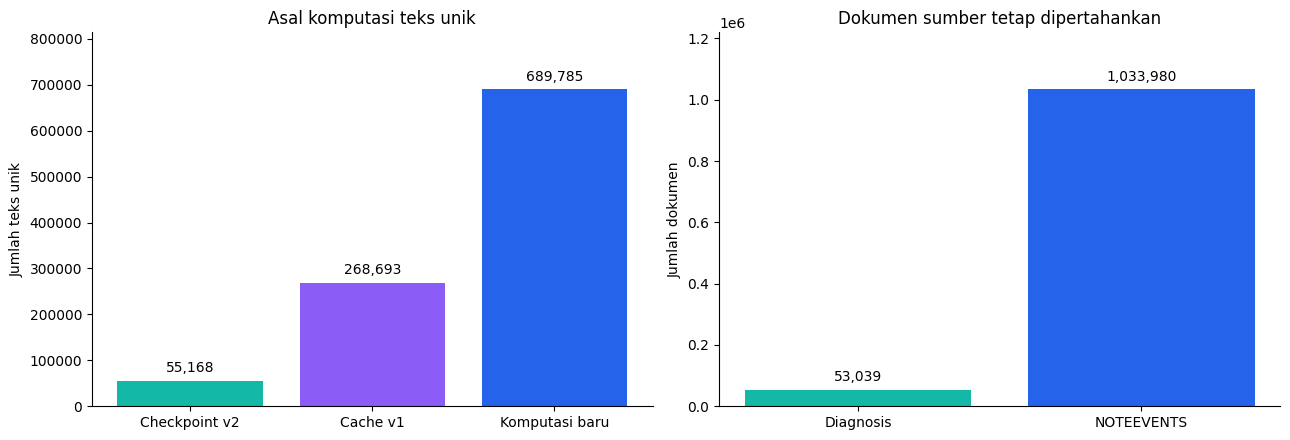

In [10]:
if metadata['status']==READY:
    import matplotlib.pyplot as plt
    c=metadata['counts']
    old=c['legacy_checkpoint_texts_preserved'];v1=c['v1_unique_texts_reused'];new=c['unique_texts']-old-v1
    fig,axes=plt.subplots(1,2,figsize=(13,4.5))
    b=axes[0].bar(['Checkpoint v2','Cache v1','Komputasi baru'],[old,v1,new],color=['#14b8a6','#8b5cf6','#2563eb'])
    axes[0].bar_label(b,labels=[f'{int(x):,}' for x in [old,v1,new]],padding=4)
    axes[0].set(title='Asal komputasi teks unik',ylabel='Jumlah teks unik')
    b=axes[1].bar(['Diagnosis','NOTEEVENTS'],[c['diagnosis_documents'],c['note_documents']],color=['#14b8a6','#2563eb'])
    axes[1].bar_label(b,labels=[f'{int(x):,}' for x in b.datavalues],padding=4)
    axes[1].set(title='Dokumen sumber tetap dipertahankan',ylabel='Jumlah dokumen')
    for ax in axes:
        ax.margins(y=.18);ax.spines[['top','right']].set_visible(False)
    fig.tight_layout();fig.savefig(report_dir/'embedding_reuse_profile.png',dpi=180,bbox_inches='tight');plt.show()
else:
    print('Grafik agregat tersedia setelah MODE build selesai.')

## Interpretasi dan batasan

Proses tidak mengubah kohort 53.044 stay, fitur numerik, total ICU LOS sebagai y, ataupun jadwal prediksi mulai jam ke-4. Tidak ada training LOS atau fitting transformasi teks di tahap ini.

Benchmark sampel dan jumlah match cache menentukan potensi penghematan; tidak ada janji bahwa sisa proses pasti selesai dalam beberapa jam. Timestamp masih proxy, pola kematian tidak menjamin screening sempurna, dan retensi penyebutan LOS/disposisi serta pretraining encoder tetap menjadi keterbatasan penelitian.

Simpan notebook. Folder run sumber tetap diperlukan karena sejumlah array lama dirujuk oleh hasil lanjutan.